# All start months: the year-3 drift rule tested, and the drift trend and test in time firmed up

Fourth notebook of `nov2026_outlook/`. It uses the Reanalysis (BruteForce) starts of every start month
(Feb, May, Aug, Nov; May and Nov every year, Feb and Aug every fifth year), not only the 1 Nov starts, to
address the two open items of `01_year3_drift_sensitivity` and `03_drift_trend_and_test`:

1. **Test the year-3 rule.** Year 3 of the 1 Nov 2026 start is corrected with
   $d_3(m) = d_2(m) + r\,[d_2(m) - d_1(m)]$ (adjusted: the change at the initial-adjustment leads 0-2 is
   replaced by the mean change of the later leads; $r = 1$ continues the drift linearly, $r = 0$ holds it).
   A 12-month step cannot be tested on 24-month hindcasts. At a fixed target month, though, starts six
   months apart (May and Nov, Feb and Aug) give the drift at leads $L-12$, $L-6$ and $L$, so the same rule
   with a 6-month step,
   $\hat d_s(L) = d_{s+6}(L-6) + r\,[d_{s+6}(L-6) - d_s(L-12)]$, predicts year 2 ($L$ = 12-23) of every start
   month from earlier leads, and can be scored. Under an exponential slow drift the 6-month factor
   $r_6 = e^{-6/T}$ fixes $T$, which the Nov starts alone could not (`01`), and gives the 12-month
   $r = r_6^2$.
2. **More start months for the drift trend and the test in time.** The drift trend of `03` rests on the
   38 Nov starts and its 2009-2018 test on 10 starts with 3 La Niña winters. Here the trend is estimated for
   every start month and pooled, and every correction is trained on the 1981-2008 starts and verified on all
   2009-2018 starts (Feb, May, Aug, Nov), scored over every 3-month season of years 1 and 2. A slope pooled
   over the start months is added as a correction method.
3. **The 1 Nov 2026 outlook** with the pooled-slope corrections and the tested year-3 $r$.

Before that, section 1 separates the drift into a lead-dependent part and a target-month part using all start
months (the other open item of `01`).

In [1]:
%matplotlib inline
import sys
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf

### Run controls

In [2]:
NOTEBOOK = "nov2026_outlook/04_start_months_and_year3_test"   # outputs: rc.OUTPUT_ROOT/nov2026_outlook/04_start_months_and_year3_test/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: recompute this notebook's products
                        # (shared Reanalysis/observation/ERA5 caches are reused; set rc.REBUILD_REFERENCE = True to redo them)
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"

YEAR, INIT = 2026, 11                       # the extended 36-month start
NLEAD_REF = rc.NLEAD                        # Reanalysis length (24)
NLEAD = rc.start_nlead(YEAR, INIT)          # 36
INITS = (2, 5, 8, 11)                       # Reanalysis start months (Feb/Aug every fifth year, May/Nov every year)
INIT_NAME = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}
PARTNER = {s: (s + 5) % 12 + 1 for s in INITS}   # start six months later: Feb-Aug, May-Nov
REF_YEARS = (1981, 2018)                    # start years read (the HadISST cache of 03 begins in 1981)
OBS_BASE = (1991, 2020)                     # observed climatology for the fixed and T1 anomalies (as 03)
DRIFT_BASES = {"1981-2010": (1981, 2010), "1991-2018": (1991, 2018)}
TRAIN, VERIFY = (1981, 2008), (2009, 2018)  # test in time (as 03)
ADJUST_LEADS = 3                            # leads 0-2: initial adjustment
STEP = 6                                    # lead step of the year-3 rule test (months)
# year-3 rule variants scored in section 2: (r, adjusted)
RULES = {
    "hold (r = 0)": (0.0, True),
    "r = 0.5, adjusted": (0.5, True),
    "r = 1, adjusted": (1.0, True),
    "r = 1, per-month (not adjusted)": (1.0, False),
}
RULE_COLORS = dict(zip(RULES, ["tab:red", "tab:olive", "tab:blue", "tab:orange"]))
INIT_COLORS = {2: "tab:green", 5: "tab:orange", 8: "tab:purple", 11: "tab:blue"}
POOL = {name: rc.CASES[name]["case_prefix"] for name in rc.POOLED_CASES}
NINO_BOX = rc.NINO_REGIONS["Nino3.4"]
TROPICAL_BOX = (0.0, 360.0, -20.0, 20.0)
OBS_PRODUCT = "HadISST1.1"
THRESHOLD = -0.5
WINTERS = {"2026/27": 1, "2027/28": 13, "2028/29": 25}
SEASON_CENTRES = {"year 1": range(1, 12), "year 2": range(12, 23)}   # centre lead of each 3-month mean
N_BOOT = 2000

DATA_DIR = rc.output_dir(NOTEBOOK, "data")
plt.rcParams.update({"font.size": 12, "axes.grid": True, "grid.alpha": 0.3})


def save(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=200))

### Load: member-level indices of every start month (cached)

Niño3.4 and the tropical ocean mean of every member of the Reanalysis starts of each start month
(init, year, member, lead; NaN where a start does not exist), the 30 members of the 1 Nov 2026 start and
HadISST 1.1, absolute °C. The Nov starts, the 2026 members and the observations are taken from the cache of
`03_drift_trend_and_test` when it is valid; the Feb, May and Aug starts are read here (about 10 minutes).

In [3]:
%%time
CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                    f"nino34_trop_members_init{''.join(f'{m:02d}' for m in INITS)}_ref{REF_YEARS[0]}-{REF_YEARS[1]}"
                    f"_y{YEAR}_l{NLEAD}_{OBS_PRODUCT}_v1.nc")
NOV_CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                        f"nino34_trop_members_init{INIT:02d}_ref{REF_YEARS[0]}-{REF_YEARS[1]}_y{YEAR}_l{NLEAD}_{OBS_PRODUCT}_v1.nc")
NOV_EXPECTED = {"ref_years": f"{REF_YEARS[0]}-{REF_YEARS[1]}", "year": YEAR, "init": INIT, "nlead": NLEAD,
                "pool": ",".join(POOL), "obs": OBS_PRODUCT}
EXPECTED = {**NOV_EXPECTED, "inits": ",".join(map(str, INITS))}
YEARS = np.arange(REF_YEARS[0], REF_YEARS[1] + 1)


def valid(path, expected):
    return path.is_file() and all(str(load_netcdf(path).attrs.get(k)) == str(v) for k, v in expected.items())


def build():
    ocean = rc.land_fraction() < 0.5
    idx = lambda da: (rc.box_mean(da, NINO_BOX).load(), rc.box_mean(da.where(ocean), TROPICAL_BOX).load())
    rn = np.full((len(INITS), YEARS.size, rc.NENS, NLEAD_REF), np.nan)
    rt = rn.copy()
    nov = load_netcdf(NOV_CACHE) if derivation_mode != "rebuild" and valid(NOV_CACHE, NOV_EXPECTED) else None
    for i, init in enumerate(INITS):
        if init == INIT and nov is not None:
            rn[i], rt[i] = nov["ref_nino"].sel(year=YEARS).values, nov["ref_trop"].sel(year=YEARS).values
            continue
        for k, y in enumerate(YEARS):
            if rc.member_file(rc.REFERENCE["case_prefix"], int(y), init, 0, "TS") is None:
                continue
            ens = rc.open_hindcast(rc.REFERENCE["case_prefix"], int(y), init, "TS")
            if ens is None:
                continue
            n, t = idx(ens)
            rn[i, k, ens["member"].values], rt[i, k, ens["member"].values] = n.values, t.values
    if nov is not None:
        fc = {v: nov[v].values for v in ("fc_nino", "fc_trop", "obs_nino", "obs_trop")}
        members, times = nov["member"].values, nov["time"].values
    else:
        fn, ft, members = [], [], []
        for name, prefix in POOL.items():
            ens = rc.open_hindcast(prefix, YEAR, INIT, "TS")
            n, t = idx(ens)
            fn.append(n.values), ft.append(t.values)
            members += [f"{rc.CASES[name]['short']}:{m}" for m in ens["member"].values]
        obs = rc.obs_monthly("TS", years=(REF_YEARS[0], YEAR), mode=derivation_mode, product=OBS_PRODUCT)
        on, ot = idx(obs)
        fc = {"fc_nino": np.concatenate(fn), "fc_trop": np.concatenate(ft), "obs_nino": on.values, "obs_trop": ot.values}
        times = [f"{t.year:04d}-{t.month:02d}" for t in obs["time"].to_index()]
    ds = xr.Dataset(
        {"ref_nino": (("init", "year", "ens", "lead"), rn), "ref_trop": (("init", "year", "ens", "lead"), rt),
         "fc_nino": (("member", "flead"), fc["fc_nino"]), "fc_trop": (("member", "flead"), fc["fc_trop"]),
         "obs_nino": ("time", fc["obs_nino"]), "obs_trop": ("time", fc["obs_trop"])},
        coords={"init": list(INITS), "year": YEARS, "ens": np.arange(rc.NENS), "lead": np.arange(NLEAD_REF),
                "member": members, "flead": np.arange(NLEAD), "time": times})
    ds.attrs.update(EXPECTED, units="degC")
    return ds


if derivation_mode != "rebuild" and valid(CACHE, EXPECTED):
    D = load_netcdf(CACHE)
else:
    D = build()
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    atomic_to_netcdf(D, CACHE)
AVAIL = {init: YEARS[np.isfinite(D["ref_nino"].sel(init=init).values).any(axis=(1, 2))] for init in INITS}
for init in INITS:
    print(f"{INIT_NAME[init]}: {AVAIL[init].size} starts ({AVAIL[init][0]}-{AVAIL[init][-1]})")
print(f"{D.sizes['member']} forecast members; HadISST {str(D.time.values[0])} to {str(D.time.values[-1])}")

Feb: 7 starts (1985-2015)
May: 38 starts (1981-2018)
Aug: 7 starts (1985-2015)
Nov: 38 starts (1981-2018)
30 forecast members; HadISST 1981-01 to 2026-09
CPU times: user 740 ms, sys: 277 ms, total: 1.02 s
Wall time: 1.03 s


### Helpers

As in `03` (`kind` "Nino3.4" or "Relative": Niño3.4 minus the tropical mean, not rescaled), generalised to any
start month. Drift = ensemble mean minus HadISST at the verification month. Corrections (model anomaly =
model − `sub`, observed anomaly = observed − `oref`):

* **fixed**: mean drift of the start years; observed climatology of `OBS_BASE`.
* **T1**: per-lead linear trend of the drift over the start years, evaluated at the trend year.
* **T2** (Kharin et al. 2012): per-lead linear trend of the model climatology; observed reference from the
  observed linear trend of each calendar month.
* **T1p / T2p**: as T1 / T2, but the slope at each lead is pooled over the four start months (a common slope
  fitted to the start-month-demeaned values); the intercept stays each start month's own mean.

Leads 24-35 of the 2026 start: the mean part by the adjusted rule with a given $r$ (`01`); the trend term,
which depends on lead and not on target month, holds its lead-23 value.

In [4]:
OBS = pd.Series(D["obs_nino"].values, index=pd.PeriodIndex(D["time"].values, freq="M"))
OBS_T = pd.Series(D["obs_trop"].values, index=OBS.index)
MLAB = "JFMAMJJASOND"


def target(y, init, lead):
    return pd.Period(year=int(y), month=int(init), freq="M") + int(lead)


def data(kind):
    # Reanalysis members (init, year, ens, lead), forecast members (member, lead), observed series
    if kind == "Nino3.4":
        return D["ref_nino"].values, D["fc_nino"].values, OBS
    return (D["ref_nino"] - D["ref_trop"]).values, (D["fc_nino"] - D["fc_trop"]).values, OBS - OBS_T


def obs_at(obs, init, years, leads=range(NLEAD_REF)):
    return np.array([[obs.get(target(y, init, L), np.nan) for L in leads] for y in years])


@lru_cache(maxsize=None)
def ens_mean(kind, init, starts):
    # (years available within starts, ensemble mean (year, lead))
    ref, _, _ = data(kind)
    years = AVAIL[init][(AVAIL[init] >= starts[0]) & (AVAIL[init] <= starts[1])]
    i = INITS.index(init)
    return years, np.nanmean(ref[i][np.searchsorted(YEARS, years)], axis=1)


@lru_cache(maxsize=None)
def drift_years(kind, init, starts):
    # per-start drift (year, lead)
    years, em = ens_mean(kind, init, starts)
    return years, em - obs_at(data(kind)[2], init, years)


def mean_drift(kind, init, years):
    # mean drift over the given start years (repeats allowed, for the bootstrap)
    yrs, dd = drift_years(kind, init, REF_YEARS)
    return dd[np.searchsorted(yrs, years)].mean(0)


def obs_clim(obs, base):
    sel = obs[(obs.index.year >= base[0]) & (obs.index.year <= base[1])]
    return sel.groupby(sel.index.month).mean()


def obs_trend(obs, years_fit):
    coef = {}
    for m in range(1, 13):
        s = obs[(obs.index.month == m) & (obs.index.year >= years_fit[0]) & (obs.index.year <= years_fit[1])]
        coef[m] = np.polyfit(s.index.year, s.values, 1)
    return lambda yr, m: np.polyval(coef[m], yr)


def year_change(c, adjusted=True):
    delta = c[12:24] - c[:12]
    return np.where(np.arange(12) < ADJUST_LEADS, delta[ADJUST_LEADS:].mean(), delta) if adjusted else delta


def extend(c, nlead, r=1.0, adjusted=True):
    # 24 -> nlead leads: year 3 = year 2 + r (year 2 - year 1), the year-to-year change adjusted
    if nlead <= NLEAD_REF:
        return c[:nlead]
    return np.r_[c[:NLEAD_REF], c[12:24] + r * year_change(c, adjusted)][:nlead]


@lru_cache(maxsize=None)
def pooled_slope(kind, quantity, starts):
    # per-lead slope (per year) common to all start months: least squares on start-month-demeaned values
    num, den = np.zeros(NLEAD_REF), 0.0
    for init in INITS:
        years, x = drift_years(kind, init, starts) if quantity == "drift" else ens_mean(kind, init, starts)
        if years.size < 2:
            continue
        yd = years - years.mean()
        num += yd @ (x - x.mean(0))
        den += yd @ yd
    return num / den


def trend_at(years, x, ty, slope=None):
    # by lead: (mean over the start years, trend term at ty); their sum is the fitted line at ty
    if slope is None:
        yd = years - years.mean()
        slope = yd @ (x - x.mean(0)) / (yd @ yd)
    return x.mean(0), slope * (ty - years.mean())


def extend_parts(base, term, nlead, r):
    # leads >= 24: the mean part by the year-3 rule (target month); the trend term depends on lead, not on
    # target month, so it holds its lead-23 value (copying it by target month makes a step at lead 24)
    return extend(base, nlead, r) + np.r_[term, np.full(max(nlead - NLEAD_REF, 0), term[-1])][:nlead]


def correction(kind, init, method, starts, eval_year, nlead=NLEAD_REF, trend_year=None, r=1.0):
    # (sub, oref) for a start on 1 init eval_year: model anomaly = model - sub; observed anomaly = obs - oref
    obs = data(kind)[2]
    ty = eval_year if trend_year is None else trend_year
    years, em = ens_mean(kind, init, starts)
    months = [target(eval_year, init, L).month for L in range(nlead)]
    if method in ("fixed", "T1", "T1p"):
        dd = em - obs_at(obs, init, years)
        if method == "fixed":
            base, term = dd.mean(0), np.zeros(NLEAD_REF)
        else:
            base, term = trend_at(years, dd, ty, pooled_slope(kind, "drift", starts) if method == "T1p" else None)
        clim = obs_clim(obs, OBS_BASE).loc[months].values
        return extend_parts(base, term, nlead, r) + clim, clim
    base, term = trend_at(years, em, ty, pooled_slope(kind, "model", starts) if method == "T2p" else None)
    tr = obs_trend(obs, (starts[0], starts[1] + 2))
    oref = np.array([tr(target(ty, init, L).year, target(ty, init, L).month) for L in range(nlead)])
    return extend_parts(base, term, nlead, r), oref


def run3(a):
    # centred 3-month mean along the last axis (NaN at the ends)
    out = np.full(a.shape, np.nan)
    out[..., 1:-1] = (a[..., :-2] + a[..., 1:-1] + a[..., 2:]) / 3.0
    return out


def djf(a, first):
    return a[..., first:first + 3].mean(-1)

### 1. The drift by lead and target month, all start months

Top: Niño3.4 drift by lead of each start month over the common start years (1985-2015 every fifth year, where
all four exist). Bottom: an additive model $d_s(L) = g(L) + h(m)$ fitted to the four start months together,
with $g$ the lead-dependent drift (initial adjustment and slow drift) and $h$ the target-month part (mean zero).
Its residual measures how much the drift depends on the start month beyond lead and target month, which is
what the 6-month test of section 2 assumes small.

common start years: (1985, 1990, 1995, 2000, 2005, 2010, 2015)


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/04_start_months_and_year3_test/figures/fig_drift_drift_by_start_month.png


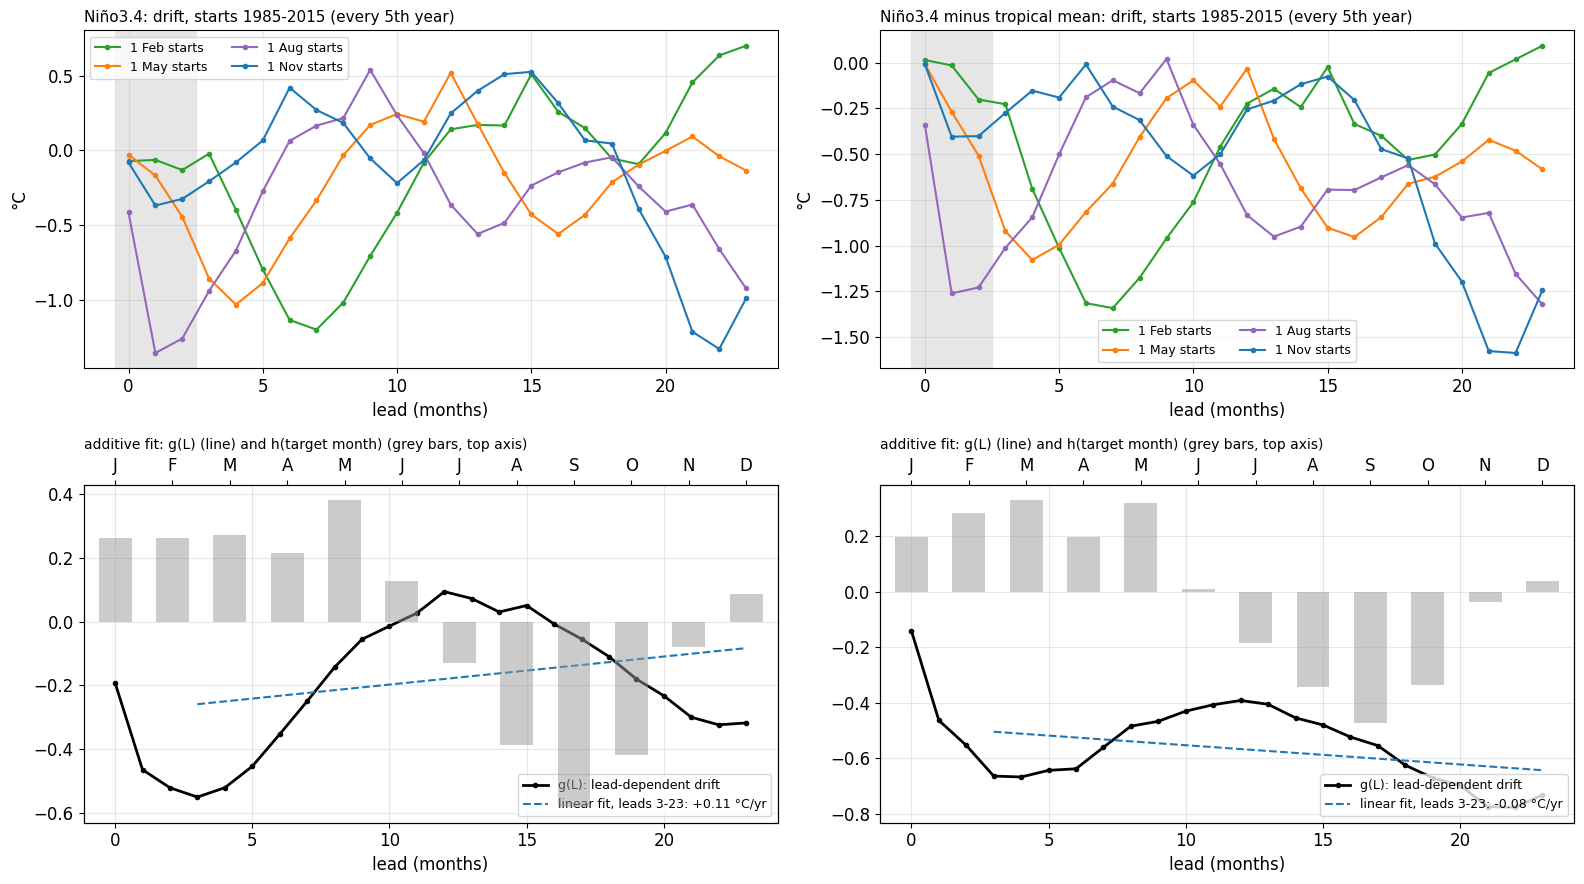

,index,g(0) (°C),g(3) - g(0),"slope of g, leads 3-23 (°C/yr)",h range (°C),residual RMS (°C),residual RMS Feb,residual RMS May,residual RMS Aug,residual RMS Nov
0,Nino3.4,-0.19,-0.36,0.11,0.96,0.30,0.45,0.10,0.26,0.30
1,Relative,-0.14,-0.52,-0.08,0.80,0.26,0.39,0.09,0.24,0.24


In [5]:
COMMON = tuple(sorted(set.intersection(*(set(AVAIL[i].tolist()) for i in INITS))))
COMMON_SPAN = (COMMON[0], COMMON[-1])
print("common start years:", COMMON)


def additive_fit(drifts):
    # drifts: {init: (24,)} -> g (24,), h (12,), residual {init: (24,)}
    rows, y = [], []
    for init, d in drifts.items():
        for L in range(NLEAD_REF):
            x = np.zeros(NLEAD_REF + 12)
            x[L], x[NLEAD_REF + target(2000, init, L).month - 1] = 1, 1
            rows.append(x), y.append(d[L])
    X, y = np.array(rows), np.array(y)
    coef = np.linalg.lstsq(X, y, rcond=None)[0]
    g, h = coef[:NLEAD_REF] + coef[NLEAD_REF:].mean(), coef[NLEAD_REF:] - coef[NLEAD_REF:].mean()
    res = {init: d - (g + h[[target(2000, init, L).month - 1 for L in range(NLEAD_REF)]]) for init, d in drifts.items()}
    return g, h, res


fig, axes = plt.subplots(2, 2, figsize=(16, 9))
rows = []
for col, kind in enumerate(("Nino3.4", "Relative")):
    drifts = {init: mean_drift(kind, init, COMMON) for init in INITS}
    g, h, res = additive_fit(drifts)
    ax = axes[0, col]
    for init, d in drifts.items():
        ax.plot(range(NLEAD_REF), d, "-o", ms=3, color=INIT_COLORS[init], label=f"1 {INIT_NAME[init]} starts")
    ax.axvspan(-0.5, ADJUST_LEADS - 0.5, color="0.9", zorder=0)
    ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean'}: drift, starts {COMMON_SPAN[0]}-{COMMON_SPAN[1]} (every 5th year)",
                 loc="left", fontsize=11)
    ax.set_xlabel("lead (months)")
    ax.set_ylabel("°C")
    ax.legend(fontsize=9, ncol=2)
    ax = axes[1, col]
    ax.plot(range(NLEAD_REF), g, "k-o", ms=3, lw=2, label="g(L): lead-dependent drift")
    slope = np.polyfit(np.arange(ADJUST_LEADS, NLEAD_REF), g[ADJUST_LEADS:], 1)[0] * 12
    ax.plot(np.arange(ADJUST_LEADS, NLEAD_REF), np.polyval(np.polyfit(np.arange(ADJUST_LEADS, NLEAD_REF), g[ADJUST_LEADS:], 1),
                                                         np.arange(ADJUST_LEADS, NLEAD_REF)),
            color="tab:blue", ls="--", label=f"linear fit, leads {ADJUST_LEADS}-23: {slope:+.2f} °C/yr")
    ax2 = ax.twiny()
    ax2.bar(np.arange(12) * (NLEAD_REF - 1) / 11, h, width=1.2, color="0.6", alpha=0.5)
    ax2.set_xticks(np.arange(12) * (NLEAD_REF - 1) / 11, list(MLAB))
    ax2.set_xlim(ax.get_xlim())
    ax2.grid(False)
    ax.set_title("additive fit: g(L) (line) and h(target month) (grey bars, top axis)", loc="left", fontsize=10)
    ax.set_xlabel("lead (months)")
    ax.legend(fontsize=9, loc="lower right")
    allres = np.concatenate(list(res.values()))
    rows.append({"index": kind, "g(0) (°C)": round(g[0], 2), f"g({ADJUST_LEADS}) - g(0)": round(g[ADJUST_LEADS] - g[0], 2),
                 f"slope of g, leads {ADJUST_LEADS}-23 (°C/yr)": round(slope, 2), "h range (°C)": round(h.max() - h.min(), 2),
                 "residual RMS (°C)": round(np.sqrt(np.mean(allres ** 2)), 2),
                 **{f"residual RMS {INIT_NAME[i]}": round(np.sqrt(np.mean(r_ ** 2)), 2) for i, r_ in res.items()}})
fig.tight_layout()
save(fig, "drift", "drift_by_start_month")
plt.show()
additive = pd.DataFrame(rows)
additive.to_csv(DATA_DIR / "drift_additive_fit.csv", index=False)
display(additive)

### 2. Test of the year-3 rule with a 6-month step

For each start month $s$ and lead $L$ = 12-23 of year 2, with $s+6$ the start six months later (same target
month at lead $L-6$):
$\hat d_s(L) = d_{s+6}(L-6) + r\,\Delta$, $\Delta = d_{s+6}(L-6) - d_s(L-12)$; *adjusted*: for
$L - 12 < 3$ (the initial-adjustment leads), $\Delta$ is replaced by the mean $\Delta$ of $L$ = 15-23.
That is the year-3 rule with 6 instead of 12 months. Drifts are means over the same start years for both
start months: May and Nov over each drift base, Feb and Aug over their common years. The fitted $r_6$
minimises the error over $L$ = 15-23 (pooled over the four start months); under an exponential slow drift
$r_6 = e^{-6/T}$ and the 12-month year-3 factor is $r = r_6^2$. Intervals: 90% bootstrap over start years.

,index,drift base,rule,r6,mean error (°C),RMSE leads 12-23 (°C),RMSE leads 15-23,RMSE Feb,RMSE May,RMSE Aug,RMSE Nov
0,Nino3.4,1981-2010,hold (r = 0),0.00,-0.12,0.41,0.42,0.45,0.17,0.64,0.22
1,Nino3.4,1981-2010,"r = 0.5, adjusted",0.50,0.02,0.38,0.39,0.39,0.07,0.63,0.18
2,Nino3.4,1981-2010,"r = 1, adjusted",1.00,0.16,0.42,0.43,0.50,0.17,0.63,0.21
3,Nino3.4,1981-2010,"r = 1, per-month (not adjusted)",1.00,0.09,0.49,0.43,0.45,0.20,0.73,0.44
4,Nino3.4,1981-2010,"fitted r6 = 0.44, adjusted",0.44,0.01,0.38,0.39,0.39,0.07,0.63,0.18
5,Nino3.4,1991-2018,hold (r = 0),0.00,-0.11,0.41,0.41,0.45,0.15,0.64,0.20
6,Nino3.4,1991-2018,"r = 0.5, adjusted",0.50,0.04,0.38,0.39,0.39,0.14,0.63,0.15
7,Nino3.4,1991-2018,"r = 1, adjusted",1.00,0.18,0.43,0.45,0.50,0.23,0.63,0.24
8,Nino3.4,1991-2018,"r = 1, per-month (not adjusted)",1.00,0.13,0.48,0.45,0.45,0.25,0.73,0.36
9,Nino3.4,1991-2018,"fitted r6 = 0.38, adjusted",0.38,0.00,0.38,0.39,0.39,0.13,0.63,0.15


,index,drift base,fitted r6,r6 90% interval,r6 May/Nov pair,r6 Feb/Aug pair,T (months),implied 12-month r = r6^2,r = 1 interval,"RMSE(r=1 adj) - RMSE(hold), 90%"
0,Nino3.4,1981-2010,0.44,-0.61 to 0.58,0.32,0.50,7.0,0.19,0.00 to 0.34,-0.01 to +0.28
1,Nino3.4,1991-2018,0.38,-0.60 to 0.47,0.16,0.50,6.0,0.14,0.00 to 0.22,+0.01 to +0.28
2,Relative,1981-2010,0.52,-1.23 to 0.73,0.14,0.62,9.0,0.27,0.00 to 0.53,-0.01 to +0.21
3,Relative,1991-2018,0.47,-1.12 to 0.59,-0.03,0.62,8.0,0.22,0.00 to 0.34,+0.00 to +0.22


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/04_start_months_and_year3_test/figures/fig_year3_rule_test_6month.png


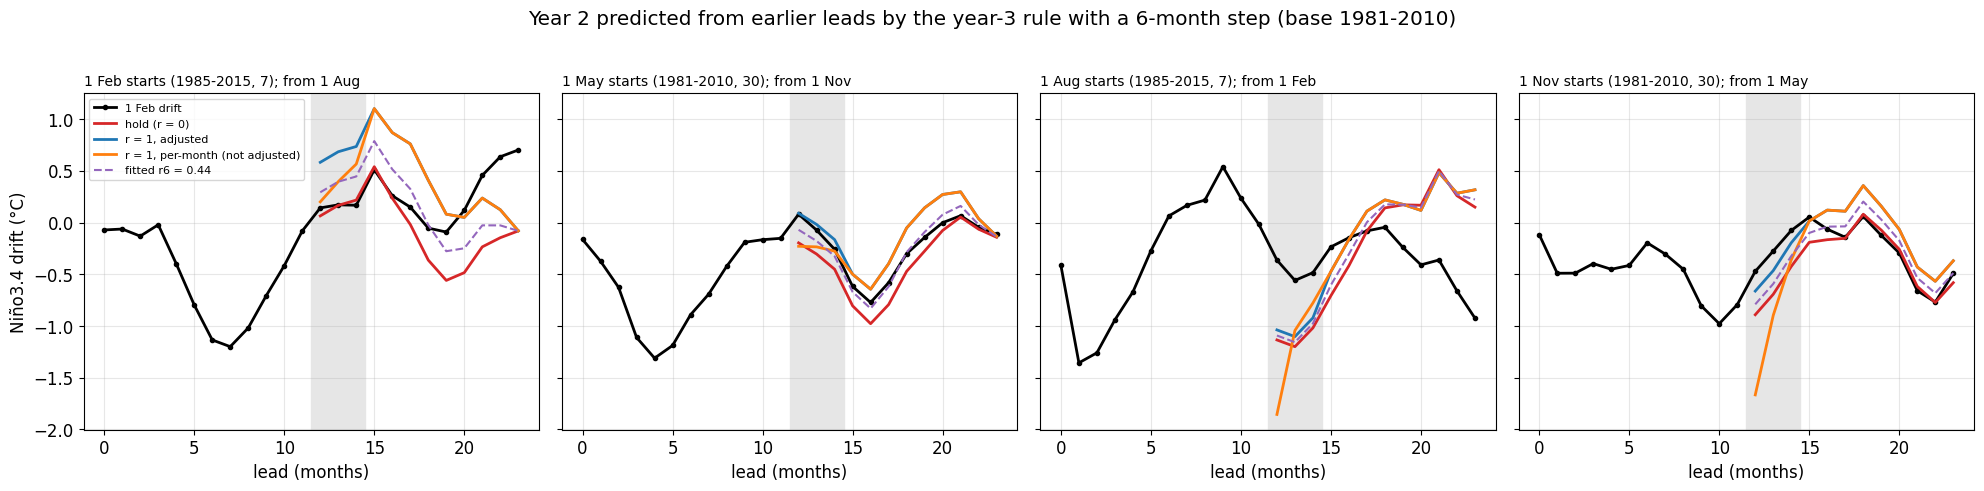

In [6]:
RULE_LEADS = np.arange(12, NLEAD_REF)
FIT_LEADS = RULE_LEADS >= 12 + ADJUST_LEADS


def pair_years(init, base):
    # start years of the pair (init, PARTNER[init]): May/Nov within the base, Feb/Aug all their common years
    yrs = np.array(sorted(set(AVAIL[init].tolist()) & set(AVAIL[PARTNER[init]].tolist())))
    return yrs[(yrs >= base[0]) & (yrs <= base[1])] if init in (5, 11) else yrs


def rule_parts(kind, init, years):
    # actual d_s(12..23), base d_{s+6}(6..17), change Delta (unadjusted)
    ds, dp = mean_drift(kind, init, years), mean_drift(kind, PARTNER[init], years)
    base = dp[RULE_LEADS - STEP]
    return ds[RULE_LEADS], base, base - ds[RULE_LEADS - 12]


def predict(base, delta, r, adjusted):
    if adjusted:
        delta = np.where(RULE_LEADS - 12 < ADJUST_LEADS, delta[FIT_LEADS].mean(), delta)
    return base + r * delta


def fit_r6(parts):
    num = sum(float(dl[FIT_LEADS] @ (a[FIT_LEADS] - b[FIT_LEADS])) for a, b, dl in parts)
    return num / sum(float(dl[FIT_LEADS] @ dl[FIT_LEADS]) for a, b, dl in parts)


rows, fits, examples = [], [], {}
for kind in ("Nino3.4", "Relative"):
    for bname, base in DRIFT_BASES.items():
        yrs = {init: pair_years(init, base) for init in INITS}
        parts = {init: rule_parts(kind, init, yrs[init]) for init in INITS}
        r6 = fit_r6(parts.values())
        rng = np.random.default_rng(0)
        boot_r6, boot_diff = [], []
        for _ in range(N_BOOT // 4):
            # resample the start years once per pair (both start months of a pair share the years)
            yb = {s: rng.choice(yrs[s], yrs[s].size, replace=True) for s in (2, 5)}
            if any(np.unique(v).size < 2 for v in yb.values()):
                continue
            bparts = {init: rule_parts(kind, init, yb[init if init in (2, 5) else PARTNER[init]]) for init in INITS}
            boot_r6.append(fit_r6(bparts.values()))
            e = {m: np.concatenate([predict(b, dl, *RULES[m]) - a for a, b, dl in bparts.values()]) for m in ("hold (r = 0)", "r = 1, adjusted")}
            boot_diff.append(np.sqrt(np.mean(e["r = 1, adjusted"] ** 2)) - np.sqrt(np.mean(e["hold (r = 0)"] ** 2)))
        lo, hi = np.percentile(boot_r6, [5, 95])
        variants = dict(RULES, **{f"fitted r6 = {r6:.2f}, adjusted": (r6, True)})
        for m, (r, adj) in variants.items():
            err = {init: predict(b, dl, r, adj) - a for init, (a, b, dl) in parts.items()}
            allerr = np.concatenate(list(err.values()))
            rows.append({"index": kind, "drift base": bname, "rule": m, "r6": round(r, 2),
                         "mean error (°C)": round(allerr.mean(), 2), "RMSE leads 12-23 (°C)": round(np.sqrt(np.mean(allerr ** 2)), 2),
                         "RMSE leads 15-23": round(np.sqrt(np.mean(np.concatenate([e[FIT_LEADS] for e in err.values()]) ** 2)), 2),
                         **{f"RMSE {INIT_NAME[i]}": round(np.sqrt(np.mean(e ** 2)), 2) for i, e in err.items()}})
        dlo, dhi = np.percentile(boot_diff, [5, 95])
        T = -STEP / np.log(r6) if 0 < r6 < 1 else np.inf
        fits.append({"index": kind, "drift base": bname, "fitted r6": round(r6, 2), "r6 90% interval": f"{lo:.2f} to {hi:.2f}",
                     "r6 May/Nov pair": round(fit_r6([parts[5], parts[11]]), 2), "r6 Feb/Aug pair": round(fit_r6([parts[2], parts[8]]), 2),
                     "T (months)": round(T, 0) if np.isfinite(T) else "inf (r6 >= 1)",
                     "implied 12-month r = r6^2": round(min(max(r6, 0), 1) ** 2, 2),
                     "r = 1 interval": f"{max(lo, 0) ** 2:.2f} to {min(hi, 1) ** 2:.2f}",
                     "RMSE(r=1 adj) - RMSE(hold), 90%": f"{dlo:+.2f} to {dhi:+.2f}"})
        examples[(kind, bname)] = (parts, r6)
rule = pd.DataFrame(rows)
rfit = pd.DataFrame(fits)
rule.to_csv(DATA_DIR / "year3_rule_test_6month.csv", index=False)
rfit.to_csv(DATA_DIR / "year3_rule_fitted_r.csv", index=False)
display(rule)
display(rfit)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharey=True)
parts, r6 = examples[("Nino3.4", "1981-2010")]
for ax, init in zip(axes, INITS):
    a, b, dl = parts[init]
    yrs = pair_years(init, DRIFT_BASES["1981-2010"])
    ax.plot(range(NLEAD_REF), mean_drift("Nino3.4", init, yrs), "k-o", ms=3, lw=2, label=f"1 {INIT_NAME[init]} drift")
    for m in ("hold (r = 0)", "r = 1, adjusted", "r = 1, per-month (not adjusted)"):
        ax.plot(RULE_LEADS, predict(b, dl, *RULES[m]), color=RULE_COLORS[m], lw=2, label=m)
    ax.plot(RULE_LEADS, predict(b, dl, r6, True), color="tab:purple", lw=1.5, ls="--", label=f"fitted r6 = {r6:.2f}")
    ax.axvspan(11.5, 11.5 + ADJUST_LEADS, color="0.9", zorder=0)
    ax.set_title(f"1 {INIT_NAME[init]} starts ({yrs[0]}-{yrs[-1]}, {yrs.size}); from 1 {INIT_NAME[PARTNER[init]]}", loc="left", fontsize=10)
    ax.set_xlabel("lead (months)")
axes[0].set_ylabel("Niño3.4 drift (°C)")
axes[0].legend(fontsize=8)
fig.suptitle("Year 2 predicted from earlier leads by the year-3 rule with a 6-month step (base 1981-2010)", y=1.02)
fig.tight_layout()
save(fig, "year3", "rule_test_6month")
plt.show()

### 3. The drift trend from every start month

Per start year, the drift averaged over year 1 (leads 3-11) and year 2 (leads 12-23), with each start
month's mean removed, against the start year; slope for each start month and pooled (one common slope).
Intervals: 90% bootstrap over start years (all start months of a resampled year kept together).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/04_start_months_and_year3_test/figures/fig_drift_trend_drift_trend_all_start_months.png


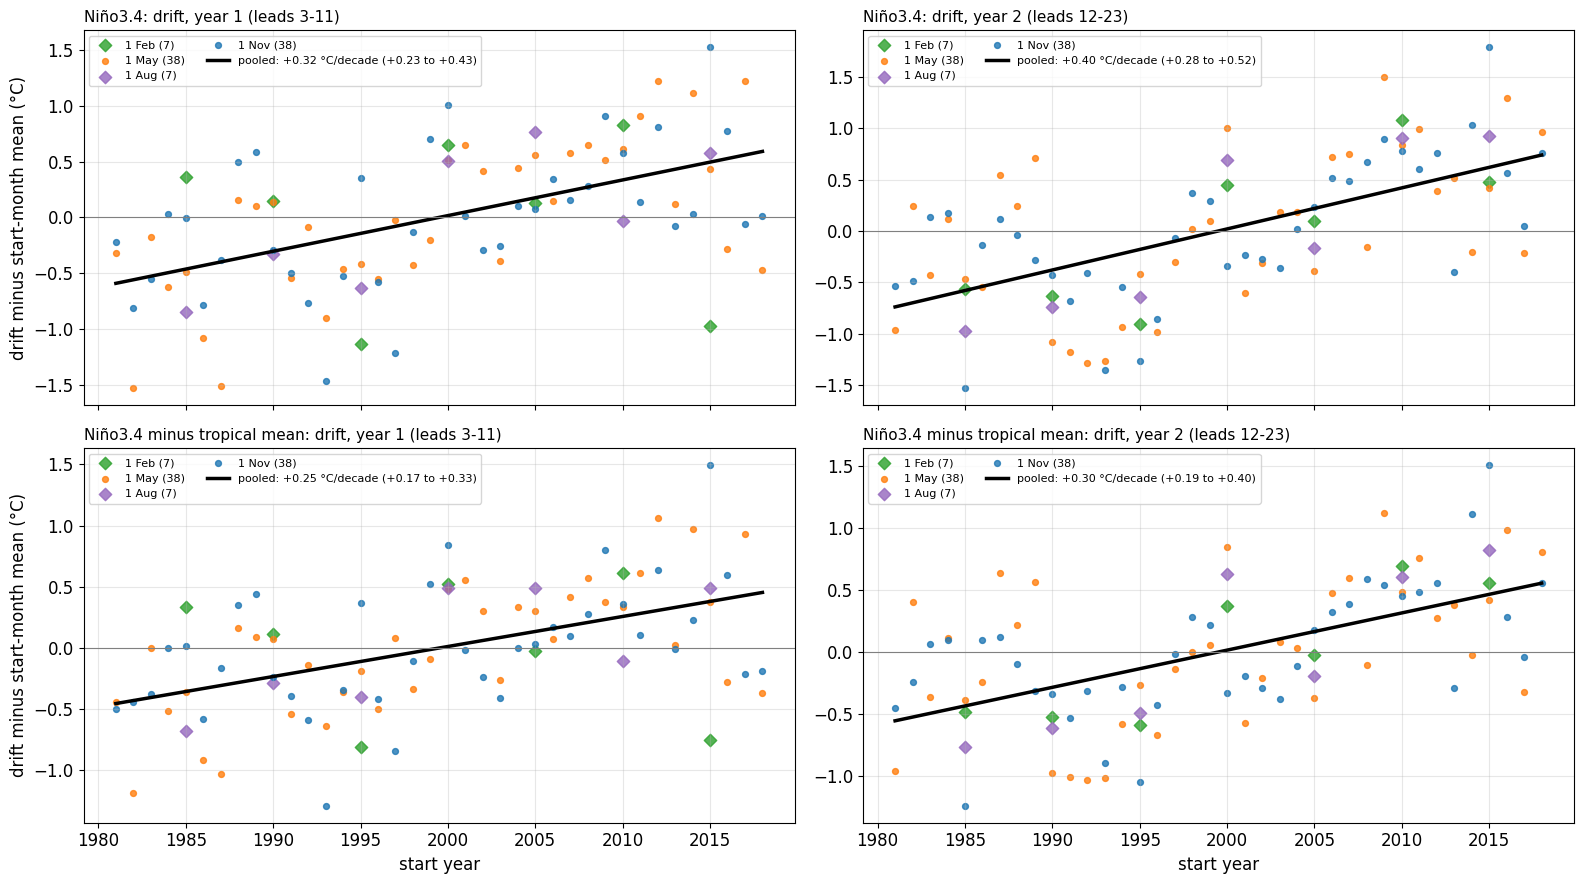

,index,drift,pooled (°C/decade),pooled 90%,Feb (°C/decade),May (°C/decade),Aug (°C/decade),Nov (°C/decade)
0,Nino3.4,year 1 (leads 3-11),0.32,+0.23 to +0.43,-0.10 (-0.57 to +0.70),+0.41 (+0.26 to +0.58),+0.45 (+0.15 to +0.81),+0.28 (+0.17 to +0.40)
1,Nino3.4,year 2 (leads 12-23),0.40,+0.28 to +0.52,+0.54 (+0.33 to +0.99),+0.35 (+0.19 to +0.51),+0.68 (+0.40 to +0.93),+0.39 (+0.26 to +0.54)
2,Relative,year 1 (leads 3-11),0.25,+0.17 to +0.33,-0.11 (-0.45 to +0.48),+0.31 (+0.20 to +0.45),+0.34 (+0.09 to +0.62),+0.22 (+0.12 to +0.32)
3,Relative,year 2 (leads 12-23),0.30,+0.19 to +0.40,+0.44 (+0.30 to +0.66),+0.25 (+0.11 to +0.39),+0.54 (+0.29 to +0.70),+0.29 (+0.18 to +0.41)


In [7]:
BUCKETS = {"year 1 (leads 3-11)": slice(ADJUST_LEADS, 12), "year 2 (leads 12-23)": slice(12, 24)}


def slope(years, x):
    yd = years - years.mean()
    return float(yd @ (x - x.mean()) / (yd @ yd))


def pooled(series):
    # series: {init: (years, values)} -> common slope of the demeaned values
    yy = np.concatenate([y - y.mean() for y, v in series.values() if y.size > 1])
    vv = np.concatenate([v - v.mean() for y, v in series.values() if y.size > 1])
    return float(yy @ vv / (yy @ yy))


rng = np.random.default_rng(0)
boot_years_all = [rng.choice(YEARS, YEARS.size, replace=True) for _ in range(N_BOOT)]
rows = []
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True)
for row, kind in enumerate(("Nino3.4", "Relative")):
    for col, (bl, sl) in enumerate(BUCKETS.items()):
        series = {}
        for init in INITS:
            yrs, dd = drift_years(kind, init, REF_YEARS)
            series[init] = (yrs.astype(float), dd[:, sl].mean(1))
        ax = axes[row, col]
        for init, (yrs, v) in series.items():
            ax.scatter(yrs, v - v.mean(), s=18 if init in (5, 11) else 40, color=INIT_COLORS[init],
                       marker="o" if init in (5, 11) else "D", label=f"1 {INIT_NAME[init]} ({yrs.size})", alpha=0.8)
        b = pooled(series)
        bs = []
        for by in boot_years_all:
            s = {}
            for init, (yrs, v) in series.items():
                k = np.concatenate([np.where(yrs == y)[0] for y in by])
                s[init] = (yrs[k], v[k])
            if all(np.unique(y_).size > 1 for y_, _ in s.values()):
                bs.append(pooled(s))
        lo, hi = np.percentile(bs, [5, 95])
        yy = np.array(REF_YEARS, float)
        ax.plot(yy, b * (yy - YEARS.mean()), "k", lw=2.5, label=f"pooled: {10 * b:+.2f} °C/decade ({10 * lo:+.2f} to {10 * hi:+.2f})")
        ax.axhline(0, color="0.5", lw=0.8)
        ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean'}: drift, {bl}", loc="left", fontsize=11)
        ax.legend(fontsize=8, ncol=2)
        row_ = {"index": kind, "drift": bl, "pooled (°C/decade)": round(10 * b, 2), "pooled 90%": f"{10 * lo:+.2f} to {10 * hi:+.2f}"}
        for init, (yrs, v) in series.items():
            sb = []
            for by in boot_years_all[:500]:
                k = np.concatenate([np.where(yrs == y)[0] for y in by])
                if np.unique(yrs[k]).size > 1:
                    sb.append(slope(yrs[k], v[k]))
            l_, h_ = np.percentile(sb, [5, 95])
            row_[f"{INIT_NAME[init]} (°C/decade)"] = f"{10 * slope(yrs, v):+.2f} ({10 * l_:+.2f} to {10 * h_:+.2f})"
        rows.append(row_)
for ax in axes[1]:
    ax.set_xlabel("start year")
for ax in axes[:, 0]:
    ax.set_ylabel("drift minus start-month mean (°C)")
fig.tight_layout()
save(fig, "drift_trend", "drift_trend_all_start_months")
plt.show()
trend = pd.DataFrame(rows)
trend.to_csv(DATA_DIR / "drift_trend_all_start_months.csv", index=False)
display(trend)

### 4. Test in time with every start month

Every correction is built from the 1981-2008 starts (of the same start month; the pooled slopes from all
four) and verified on the 2009-2018 starts: 10 May and 10 Nov starts, and Feb and Aug 2010 and 2015.
Scores over every 3-month mean of year 1 (centred on leads 1-11) and year 2 (leads 12-22): mean bias and RMSE
of the ensemble mean, and the Brier score of the La Niña probability (member fraction ≤ −0.5 °C). The
3-month seasons of one start are not independent, so the intervals (90%, bootstrap over verification years,
every start of a resampled year kept) are the measure of significance, not the season count. The DJF rows of
the Nov starts reproduce `03`.

/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)


/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)


/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)


/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)


/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)


/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)
/tmp/ipykernel_743752/1350725711.py:32: RuntimeWarning: Mean of empty slice
  e3 = np.nanmean(f3, 0)


... (245 outputs left out)

/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])


/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])


/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
/tmp/ipykernel_743752/1350725711.py:102: RuntimeWarning: Mean of empty slice
  v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/04_start_months_and_year3_test/figures/fig_drift_trend_test_in_time_all_start_months_bias.png


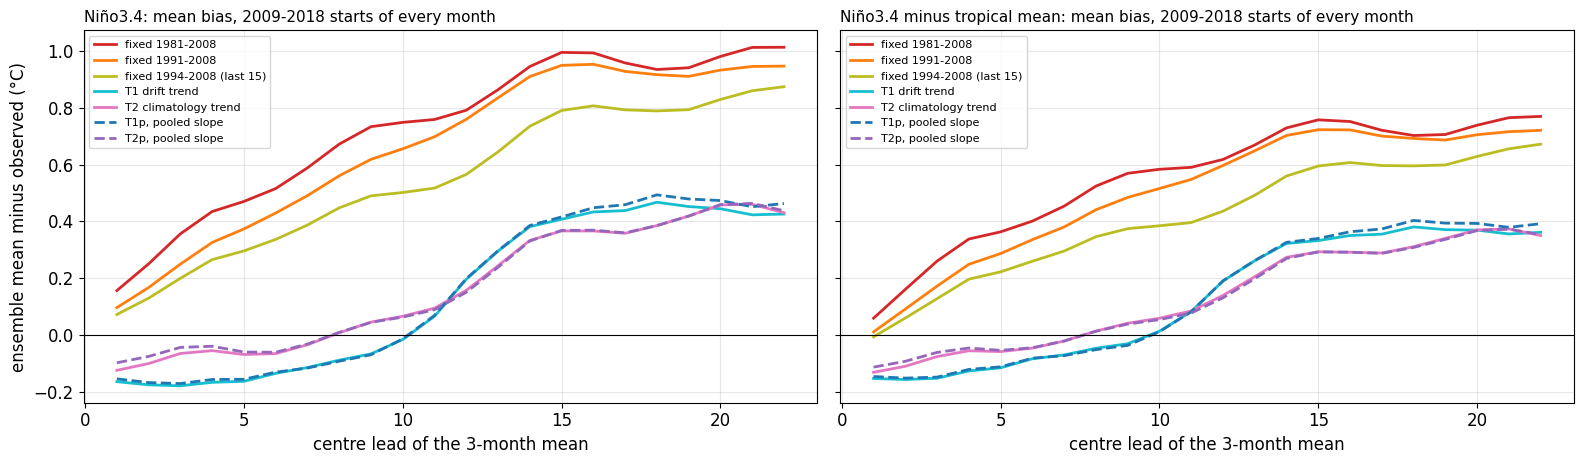

In [8]:
METHODS_TEST = {
    "fixed 1981-2008": ("fixed", TRAIN),
    "fixed 1991-2008": ("fixed", (1991, 2008)),
    "fixed 1994-2008 (last 15)": ("fixed", (1994, 2008)),
    "T1 drift trend": ("T1", TRAIN),
    "T2 climatology trend": ("T2", TRAIN),
    "T1p, pooled slope": ("T1p", TRAIN),
    "T2p, pooled slope": ("T2p", TRAIN),
}
TEST_COLORS = dict(zip(METHODS_TEST, ["tab:red", "tab:orange", "tab:olive", "tab:cyan", "tab:pink", "tab:blue", "tab:purple"]))


def verify(kind, init, mkey):
    method, starts = METHODS_TEST[mkey]
    ref, _, obs = data(kind)
    out = []
    for y in AVAIL[init][(AVAIL[init] >= VERIFY[0]) & (AVAIL[init] <= VERIFY[1])]:
        sub, oref = correction(kind, init, method, starts, y)
        k = int(np.where(YEARS == y)[0][0])
        fc = ref[INITS.index(init), k] - sub[None, :]
        ob = obs_at(obs, init, [y])[0] - oref
        out.append((int(y), fc, ob))
    return out


SC = {}   # (kind, mkey, init, year) -> per-season arrays for each lead year
for kind in ("Nino3.4", "Relative"):
    for mkey in METHODS_TEST:
        for init in INITS:
            for y, fc, ob in verify(kind, init, mkey):
                f3, o3 = run3(fc), run3(ob)
                e3 = np.nanmean(f3, 0)
                for lab, cen in SEASON_CENTRES.items():
                    c = list(cen)
                    p = np.nanmean(f3[:, c] <= THRESHOLD, axis=0)
                    evt = (o3[c] <= THRESHOLD).astype(float)
                    SC[(kind, mkey, init, y, lab)] = {"err": e3[c] - o3[c], "bs": (p - evt) ** 2, "evt": evt,
                                                       "djf_err": djf(np.nanmean(fc, 0), 1 if lab == "year 1" else 13) - djf(ob, 1 if lab == "year 1" else 13)}


def collect(kind, mkey, lab, inits=INITS, years=None):
    keys = [k for k in SC if k[0] == kind and k[1] == mkey and k[4] == lab and k[2] in inits]
    if years is not None:
        keys = [(kind, mkey, i, y, lab) for y in years for i in inits if (kind, mkey, i, y, lab) in SC]
    return keys


rows = []
for kind in ("Nino3.4", "Relative"):
    for lab in SEASON_CENTRES:
        for scope, inits in (("all start months", INITS), ("Nov only", (11,)), ("May only", (5,)), ("Feb + Aug", (2, 8))):
            for mkey in METHODS_TEST:
                ks = collect(kind, mkey, lab, inits)
                err = np.concatenate([SC[k]["err"] for k in ks])
                bs = np.concatenate([SC[k]["bs"] for k in ks])
                evt = np.concatenate([SC[k]["evt"] for k in ks])
                rows.append({"index": kind, "lead year": lab, "starts": f"{scope} ({len(ks)})", "method": mkey,
                             "mean bias (°C)": round(err.mean(), 2), "RMSE (°C)": round(np.sqrt(np.mean(err ** 2)), 2),
                             "Brier (La Niña)": round(bs.mean(), 3), "La Niña seasons observed": f"{int(evt.sum())}/{evt.size}"})
test = pd.DataFrame(rows)
test.to_csv(DATA_DIR / "test_in_time_all_start_months.csv", index=False)
with pd.option_context("display.max_rows", 200):
    display(test[test["starts"].str.startswith("all")])

# sanity check against 03: Nov starts, DJF ensemble-mean bias
chk = pd.DataFrame([{"method": m, **{f"Nov DJF bias, {lab}": round(np.mean([SC[k]["djf_err"] for k in collect("Nino3.4", m, lab, (11,))]), 2)
                                      for lab in SEASON_CENTRES}} for m in METHODS_TEST])
display(chk)

# bootstrap over verification years: score difference from the first method, all start months
vyears = np.arange(VERIFY[0], VERIFY[1] + 1)
rng = np.random.default_rng(0)
boots = [rng.choice(vyears, vyears.size, replace=True) for _ in range(N_BOOT)]
base_key = list(METHODS_TEST)[0]
ci = []
for kind in ("Nino3.4", "Relative"):
    for lab in SEASON_CENTRES:
        for mkey in list(METHODS_TEST)[1:]:
            for metric, name in (("err", "MSE"), ("bs", "Brier")):
                def score(m, yrs):
                    v = np.concatenate([SC[k][metric] for k in collect(kind, m, lab, INITS, yrs)])
                    return np.mean(v ** 2) if metric == "err" else np.mean(v)
                diff = [score(mkey, b) - score(base_key, b) for b in boots]
                full = score(mkey, vyears) - score(base_key, vyears)
                lo, hi = np.percentile(diff, [5, 95])
                ci.append({"index": kind, "lead year": lab, "method": mkey, "metric": name,
                           f"difference from {base_key}": round(full, 3), "90% interval": f"{lo:+.3f} to {hi:+.3f}",
                           "significant": "yes" if (lo > 0 or hi < 0) else ""})
ci = pd.DataFrame(ci)
ci.to_csv(DATA_DIR / "test_in_time_all_start_months_ci.csv", index=False)
with pd.option_context("display.max_rows", 200):
    display(ci)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
for ax, kind in zip(axes, ("Nino3.4", "Relative")):
    for mkey in METHODS_TEST:
        bias = []
        for cen in range(1, 23):
            v = []
            for init in INITS:
                for y, fc, ob in verify(kind, init, mkey):
                    v.append(np.nanmean(run3(fc), 0)[cen] - run3(ob)[cen])
            bias.append(np.mean(v))
        ax.plot(range(1, 23), bias, color=TEST_COLORS[mkey], lw=2, ls="--" if "pooled" in mkey else "-", label=mkey)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean'}: mean bias, 2009-2018 starts of every month",
                 loc="left", fontsize=11)
    ax.set_xlabel("centre lead of the 3-month mean")
    ax.legend(fontsize=8)
axes[0].set_ylabel("ensemble mean minus observed (°C)")
fig.tight_layout()
save(fig, "drift_trend", "test_in_time_all_start_months_bias")
plt.show()

### 5. The 1 Nov 2026 outlook with the pooled slopes and the tested year-3 factor

The 30 pooled members corrected by each method (as `03`, starts 1981-2018 or the base shown) with year 3 from
the adjusted rule at $r = 0$, $r = 1$ and the $r$ implied by section 2 (Niño3.4, base 1981-2010, $r = r_6^2$),
applied to the mean drift; trend terms hold their lead-23 value. The table gives the ensemble-mean step from
Oct to Nov 2028 (lead 23 → 24), the continuity check of `01`; the figure uses $r = 1$.
P(La Niña 2027/28) does not depend on $r$.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/04_start_months_and_year3_test/figures/fig_nov2026_outlook_pooled_slope_tested_r.png


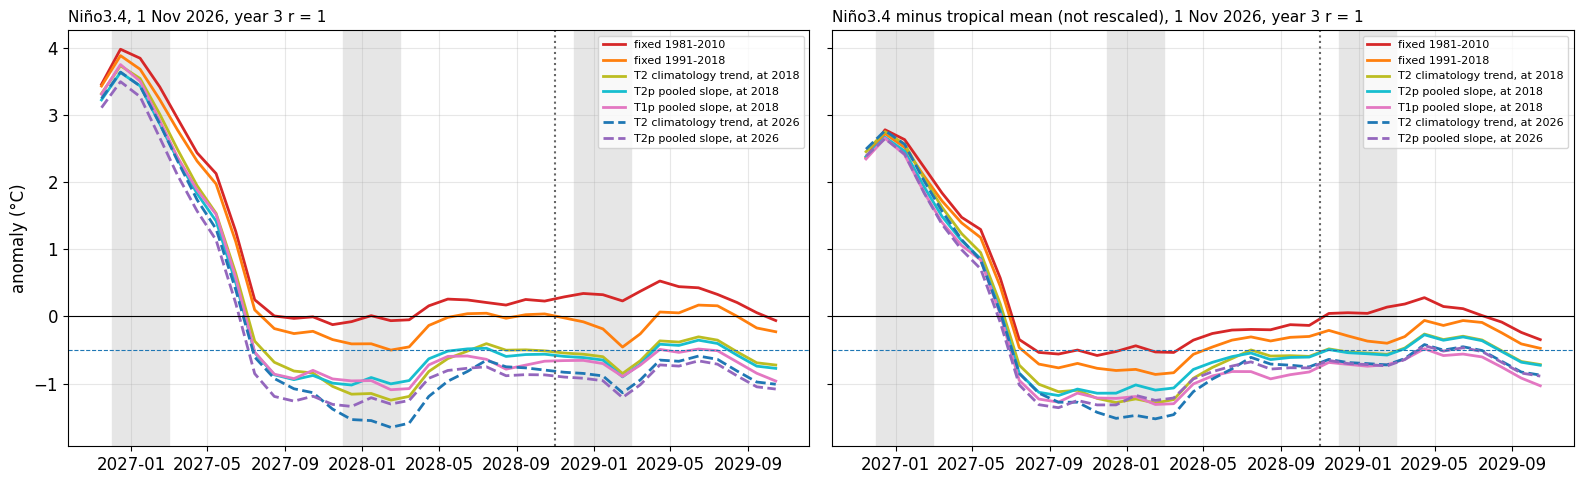

,index,method,P(LN 27/28),"P(LN 28/29), r = 0","P(both), r = 0","step Oct→Nov 2028, r = 0","P(LN 28/29), r = 0.19 (tested)","P(both), r = 0.19 (tested)","step Oct→Nov 2028, r = 0.19 (tested)","P(LN 28/29), r = 1","P(both), r = 1","step Oct→Nov 2028, r = 1"
0,Nino3.4,fixed 1981-2010,0.30,0.17,0.07,0.32,0.20,0.10,0.27,0.27,0.10,0.06
1,Nino3.4,fixed 1991-2018,0.57,0.30,0.17,0.29,0.30,0.17,0.23,0.40,0.23,-0.06
2,Nino3.4,"T2 climatology trend, at 2018",0.80,0.40,0.30,0.27,0.43,0.33,0.21,0.50,0.40,-0.03
3,Nino3.4,"T2p pooled slope, at 2018",0.73,0.40,0.27,0.27,0.43,0.30,0.21,0.53,0.40,-0.03
4,Nino3.4,"T1p pooled slope, at 2018",0.73,0.43,0.30,0.33,0.43,0.30,0.27,0.57,0.43,0.01
5,Nino3.4,"T2 climatology trend, at 2026",0.83,0.50,0.43,0.27,0.50,0.43,0.21,0.63,0.57,-0.03
6,Nino3.4,"T2p pooled slope, at 2026",0.80,0.50,0.40,0.27,0.50,0.40,0.21,0.63,0.53,-0.03
7,Relative,fixed 1981-2010,0.57,0.27,0.17,0.27,0.27,0.17,0.25,0.27,0.17,0.18
8,Relative,fixed 1991-2018,0.73,0.33,0.20,0.24,0.40,0.27,0.21,0.43,0.30,0.09
9,Relative,"T2 climatology trend, at 2018",0.83,0.43,0.37,0.21,0.43,0.37,0.19,0.50,0.43,0.11


In [9]:
METHODS_2026 = {
    "fixed 1981-2010": ("fixed", (1981, 2010), None),
    "fixed 1991-2018": ("fixed", (1991, 2018), None),
    "T2 climatology trend, at 2018": ("T2", REF_YEARS, 2018),
    "T2p pooled slope, at 2018": ("T2p", REF_YEARS, 2018),
    "T1p pooled slope, at 2018": ("T1p", REF_YEARS, 2018),
    "T2 climatology trend, at 2026": ("T2", REF_YEARS, None),
    "T2p pooled slope, at 2026": ("T2p", REF_YEARS, None),
}
R_TESTED = float(rfit.query("index == 'Nino3.4' and `drift base` == '1981-2010'")["implied 12-month r = r6^2"].iloc[0])
R_VALUES = {"r = 0": 0.0, f"r = {R_TESTED:.2f} (tested)": R_TESTED, "r = 1": 1.0}
rows = []
x = [target(YEAR, INIT, L).to_timestamp() + pd.Timedelta(days=14) for L in range(NLEAD)]
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, kind in zip(axes, ("Nino3.4", "Relative")):
    _, fc, _ = data(kind)
    for (mkey, (method, starts, ty)), c in zip(METHODS_2026.items(), list(TEST_COLORS.values())):
        row = {"index": kind, "method": mkey}
        for rlab, r in R_VALUES.items():
            sub, _ = correction(kind, INIT, method, starts, YEAR, NLEAD, trend_year=ty, r=r)
            a = fc - sub[None, :]
            v = {w: djf(a, first) for w, first in WINTERS.items()}
            ln = {w: v[w] <= THRESHOLD for w in v}
            if r == 0.0:
                row["P(LN 27/28)"] = round(ln["2027/28"].mean(), 2)
            row[f"P(LN 28/29), {rlab}"] = round(ln["2028/29"].mean(), 2)
            row[f"P(both), {rlab}"] = round((ln["2027/28"] & ln["2028/29"]).mean(), 2)
            row[f"step Oct→Nov 2028, {rlab}"] = round(float(a.mean(0)[NLEAD_REF] - a.mean(0)[NLEAD_REF - 1]), 2)
            if r == 1.0:
                ax.plot(x, a.mean(0), color=c, lw=2, ls="--" if "2026" in mkey else "-", label=mkey)
        rows.append(row)
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(THRESHOLD, color="tab:blue", ls="--", lw=0.8)
    ax.axvline(x[NLEAD_REF] - pd.Timedelta(days=14), color="0.4", ls=":")
    for first in WINTERS.values():
        ax.axvspan(x[first] - pd.Timedelta(days=14), x[first + 2] + pd.Timedelta(days=14), color="0.9", zorder=0)
    ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Niño3.4 minus tropical mean (not rescaled)'}, 1 Nov 2026, year 3 r = 1",
                 loc="left", fontsize=11)
    ax.legend(fontsize=8)
axes[0].set_ylabel("anomaly (°C)")
fig.tight_layout()
save(fig, "nov2026", "outlook_pooled_slope_tested_r")
plt.show()
p2026 = pd.DataFrame(rows)
p2026.to_csv(DATA_DIR / "nov2026_la_nina_pooled_slope_tested_r.csv", index=False)
with pd.option_context("display.max_columns", 30, "display.width", 250):
    display(p2026)

### Findings

**1. Drift structure (all four start months, common starts 1985-2015).** An additive model, lead-dependent
drift $g(L)$ plus target-month part $h(m)$, fits the Niño3.4 drift to 0.30 °C RMS (0.10 May, 0.26-0.30 Aug/Nov,
0.45 Feb): the drift depends on the start month beyond lead and target month, most for Feb. In $g$, the
initial adjustment is −0.36 °C over leads 0-3, after which the slow drift is small (+0.11 °C/yr for Niño3.4,
−0.08 for the relative index).

**2. The year-3 rule, tested with a 6-month step, does not support linear continuation ($r = 1$).**

| Niño3.4, base 1981-2010 | RMSE leads 12-23 (°C) |
|---|---|
| hold ($r_6 = 0$) | 0.41 |
| $r_6 = 0.5$, adjusted | 0.38 |
| $r_6 = 1$, adjusted | 0.42 |
| $r_6 = 1$, per-month (not adjusted) | 0.49 |

* The best factor is $r_6$ = 0.44 (1981-2010) or 0.38 (1991-2018); separately 0.16-0.32 for the May/Nov pair
  and 0.50 for Feb/Aug. That is $T \approx$ 6-9 months, and a 12-month year-3 factor $r = r_6^2 \approx$ 0.14-0.27
  (90% upper bound 0.2-0.5). $r = 1$ is no better than holding the drift, and worse with the 1991-2018 base
  (RMSE difference +0.01 to +0.28). The adjustment (dropping leads 0-2 from the change) is confirmed: without it
  the error is largest.
* Caveat: the test assumes the drift at a fixed lead and target month does not depend on the start month.
  The additive residual (0.3 °C) is as large as the drift change being tested, and the Feb/Aug errors
  (0.4-0.6 °C) are the same for every $r$. The May/Nov pair, the best sampled, also prefers $r_6 < 0.5$.
* **It conflicts with the continuity check.** At $r \approx 0.2$ every Niño3.4 correction of the 2026 start
  steps by +0.21 to +0.27 °C from Oct to Nov 2028; at $r = 1$, by −0.06 to +0.06 °C (section 5, `01`). Of the
  two constraints the 6-month test is the weaker (it rests on start-month independence), so $r = 1$ stays the
  default. `06_year3_drift_asymptote` rules out $r \approx 0.2$ for Niño3.4: against the free-running
  large ensemble the hindcast drift is still building in year 2, which gives $r \gtrsim 1$.

**3. The drift trend holds for every start month.** Niño3.4 drift trend pooled over the four start months:
+0.32 °C/decade in year 1 (90%: +0.23 to +0.43) and +0.40 in year 2 (+0.28 to +0.52). In year 2 every start month
is positive with an interval excluding zero (Feb +0.54, May +0.35, Aug +0.68, Nov +0.39). The relative index:
+0.25 and +0.30. The trend is not a sampling artefact of the Nov starts.

**4. Test in time with every start month** (24 starts in 2009-2018, 264 seasons per lead year, 72-77 La Niña
seasons, against 10 starts and 3 winters in `03`):

| Niño3.4 | bias yr 1 | bias yr 2 | RMSE yr 2 | Brier LN yr 2 |
|---|---|---|---|---|
| fixed 1981-2008 | +0.52 | +0.95 | 1.22 | 0.230 |
| fixed 1994-2008 (last 15) | +0.33 | +0.77 | 1.07 | 0.211 |
| T1 drift trend | −0.11 | +0.40 | 0.87 | 0.190 |
| T2 climatology trend | −0.03 | +0.36 | 0.83 | (0.129) |
| T1p, pooled slope | −0.10 | +0.42 | 0.89 | 0.204 |
| T2p, pooled slope | −0.02 | +0.36 | 0.83 | (0.129) |

* Every trend method cuts the MSE significantly in year 2, and all but T1 in year 1. The pooled slope does
  as well as each start month's own slope, and better in year 1 (RMSE 0.68 against 0.77 for T1).
* The Brier score still does not separate the fixed-base methods (T1 −0.04, interval spanning zero). The T2
  and T2p values (in brackets) are scored against a moving base with fewer events (43 against 77), so they are
  not comparable. The Nov DJF rows reproduce `03` exactly.

**5. 2026, Niño3.4** (P(LN 27/28) / P(LN 28/29) / P(both); year 3 at $r = 1$, then the tested $r = 0.19$; the
trend term held at its lead-23 value):

| | $r = 1$ | $r = 0.19$ |
|---|---|---|
| fixed 1981-2010 | 0.30 / 0.27 / 0.10 | 0.30 / 0.20 / 0.10 |
| fixed 1991-2018 | 0.57 / 0.40 / 0.23 | 0.57 / 0.30 / 0.17 |
| T2 at 2018 | 0.80 / 0.50 / 0.40 | 0.80 / 0.43 / 0.33 |
| T2p (pooled slope) at 2018 | 0.73 / 0.53 / 0.40 | 0.73 / 0.43 / 0.30 |
| T2 at 2026 | 0.83 / 0.63 / 0.57 | 0.83 / 0.50 / 0.43 |

P(La Niña 2027/28) is set by the trend correction and stays 0.73-0.80 at 2018. P(La Niña 2028/29) is about 0.5
with a trend correction at $r = 1$, and 0.1 lower at the tested $r$ (which leaves the Nov 2028 step).